In [1]:
import json 
import os 
import math

import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
import tiktoken

from importlib.metadata import version

In [2]:
GPT_CONFIG = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
}

In [3]:
import json
import os

def import_from_ipynb(nb_path, *names):
    """Execute notebook code cells that define classes/functions/configs, skipping test runs."""
    candidates = [
        nb_path,
        os.path.join(os.path.dirname(__file__) if '__file__' in locals() else '.', nb_path),
        os.path.abspath(f"src/buildinglargelanguagemodel/LLM/{nb_path}"),
        f"/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/LLM/{nb_path}"
    ]
    resolved_path = next((p for p in candidates if os.path.exists(p)), None)
    if not resolved_path:
        raise FileNotFoundError(f"Could not find {nb_path}.")

    with open(resolved_path, "r", encoding="utf-8") as f:
        nb_data = json.load(f)

    skip_signatures = [
        "logits = model(batch)",
        "start_context =",
        "layer_sizes =",
        "batch = torch.tensor",
        "out_ffn = ffn(",
        "out_att = att(",
        "out_block = block(",
        "ln_out = ln(",
        "y_gelu = gelu(x)",
        "total_params = sum("
    ]

    code_blocks = []
    for cell in nb_data.get("cells", []):
        if cell.get("cell_type") == "code":
            src = "".join(cell.get("source", []))
            if any(sig in src for sig in skip_signatures):
                continue
            code_blocks.append(src)

    exec_scope = {}
    exec("\n\n".join(code_blocks), exec_scope)
    return [exec_scope[name] for name in names]

GPTModel, generate_text_simple = import_from_ipynb("llm_architecture.ipynb", "GPTModel", "generate_text_simple")

Successfully imported CausalMultiHeadSelfAttention from: /home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/Attention/multihead_self_attention.ipynb


In [4]:
torch.manual_seed(123)

model = GPTModel(GPT_CONFIG)
model.eval()

print("Model initialized successfully!")
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Model initialized successfully!
Total parameters: 162419712


In [5]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)

        logits = logits[:, -1, :]
        probas = torch.softmax(logits, dim=-1)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)

        idx = torch.cat((idx, idx_next), dim=1)

    return idx

In [6]:
def text_to_token_ids(text, tokenizer):

    encoded = tokenizer.encode(text, allowed_special = {"<|endoftext|>"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)

    return encoded_tensor 

In [7]:
start_context = "non of the above"

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = text_to_token_ids(start_context, tokenizer)
token_ids 

tensor([[13159,   286,   262,  2029]])

In [8]:
def token_ids_to_text(token_ids , tokenizer):

    flat = token_ids.squeeze(0)

    return tokenizer.decode(flat.tolist())

token_ids_to_text(token_ids, tokenizer)

'non of the above'

In [9]:
token_ids = generate_text_simple(

    model = model,
    idx = text_to_token_ids(start_context, tokenizer),
    max_new_tokens = 10,
    context_size = GPT_CONFIG["context_length"]
)

In [10]:
token_ids.squeeze_(0)

tensor([13159,   286,   262,  2029, 24075,  7901, 48218, 13772, 29924, 35075,
        39357, 17297, 13981, 10274])

In [11]:
token_ids_to_text(token_ids, tokenizer)

'non of the above Wisdom commitment Bridgewater blamed repo juicy698 Jin MLS Ban'

In [12]:
# log_probs = torch.log(torch.cat((target_probas_1 , target_probas_2)))
# -1*torch.mean(log_probs)
# print(log_probs)

In [13]:
with open("/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/data/train.txt", "r") as file:
    content = file.read()
    print(content[:100])

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with


In [14]:
total_character = len(content)
total_token = len(tokenizer.encode(content))

print("Characters:", total_character)
print("Tokens:", total_token)

Characters: 44657029
Tokens: 11139413


In [15]:
import torch
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt,allowed_special={"<|endoftext|>"})            
            
        for i in range(0, len(token_ids) - max_length, stride):

            input_chunk = token_ids[i : i + max_length]

            target_chunk = token_ids[i + 1 : i + max_length + 1]

            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [16]:
def create_dataloader_v1(txt, batch_size = 4, max_length = 256, stride = 128, shuffle = True, drop_last = True, num_workers = 0):

    tokenizer = tiktoken.get_encoding("gpt2")

    dataset = GPTDatasetV1(txt , tokenizer ,max_length, stride)

    dataloader = DataLoader(
        dataset,
        batch_size = batch_size,
        shuffle = shuffle,
        drop_last = drop_last,
        num_workers = num_workers,
    )

    return dataloader

In [17]:
train_ratio = 0.90
split_idx = int(train_ratio * len(content))
train_data = content[:split_idx]
val_data = content[split_idx:]

In [18]:
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size = 2,
    max_length = GPT_CONFIG['context_length'],
    stride = GPT_CONFIG['context_length'],
    drop_last = True,
    shuffle = True,
    num_workers = 0
)


val_loader = create_dataloader_v1(
    val_data,
    batch_size = 2,
    max_length = GPT_CONFIG['context_length'],
    stride = GPT_CONFIG['context_length'],
    drop_last = False,
    shuffle = False,
    num_workers = 0
)

In [19]:
print("Train data")
for x , y in train_loader:
    print(x.shape , y.shape)

Train data
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) to

In [20]:
print("Val data")
for x , y in val_loader:
    print(x.shape , y.shape)

Val data
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torc

In [21]:
train_tokens = 0
for input_batch , target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch , target_batch in val_loader:
    val_tokens += input_batch.numel()

print("Train Tokens:", train_tokens)
print("Validation tokens", val_tokens)
print("Total tokens", train_tokens + val_tokens)

Train Tokens: 10029056
Validation tokens 1110016
Total tokens 11139072


In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device 

device(type='cuda')

In [23]:
def calc_loss_batch(input_batch, target_batch, model, device):

    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)

    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):

    total_loss = 0.

    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
        
    return total_loss / num_batches

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    major, minor = map(int, torch.__version__.split(".")[:2])
    if (major, minor) >= (2, 9):
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
else:
    device = torch.device("cpu")


print(f"Using {device} device.")


model.to(device)


torch.manual_seed(123)

with torch.no_grad(): 
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Using cuda device.


In [ ]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1


    for epoch in range(num_epochs):
        model.train()  
        
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() 
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() 
            optimizer.step() 
            tokens_seen += input_batch.numel()
            global_step += 1

            
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

       
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen


def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()


In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 9.823, Val loss 9.928
Ep 1 (Step 000005): Train loss 8.068, Val loss 8.336
Every effort moves you,.                                                
Ep 2 (Step 000010): Train loss 6.620, Val loss 7.045
Ep 2 (Step 000015): Train loss 6.045, Val loss 6.600
Every effort moves you, and,, and, and, and,,, and,.                                   
Ep 3 (Step 000020): Train loss 5.532, Val loss 6.496
Ep 3 (Step 000025): Train loss 5.412, Val loss 6.376
Every effort moves you, and to the of the of the of the, and I had. Gis, and, and, and, and, and, and I had the of the to the, and, and, and, and, and, and, and
Ep 4 (Step 000030): Train loss 4.989, Val loss 6.307
Ep 4 (Step 000035): Train loss 4.612, Val loss 6.254
Every effort moves you.  "I the picture.                    "I"I the donkey he had been the picture.          
Ep 5 (Step 000040): Train loss 4.026, Val loss 6.143
Every effort moves you know the                          "Oh, and the fact- it.           

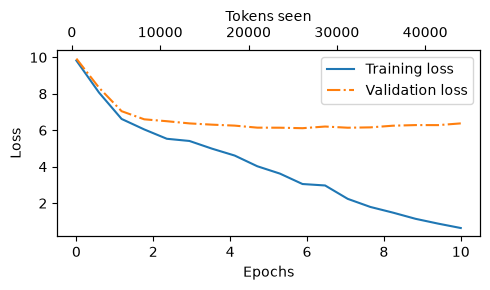

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  
    ax2 = ax1.twiny()  
    ax2.plot(tokens_seen, train_losses, alpha=0)  
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  
    plt.savefig("loss-plot.pdf")
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)